# 🧠 Run ML: three models compete to predict your 5K
[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/didilelass/didilelass/blob/main/run-ml/run_ml_colab.ipynb)

This notebook runs the full Run ML pipeline:
1. **Load runs**: sample data, or your own export from a running app or watch
2. **Build features** from the training before each race or tempo run
3. **Three models compete**: ridge regression, random forest and gradient boosting, scored with time-series cross-validation (train on the past, test on the future)
4. **Predict your 5K** with the winner, see **what matters most**, and get the **best 4-week plans**

👉 In Colab, click **Runtime → Run all**. The code lives in the [`runml`](https://github.com/didilelass/didilelass/tree/main/run-ml/runml) package.

## 1. Setup

In [1]:
# In Colab: download the code. Locally: use the repo you're already in.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("runml"):
    !git clone -q --depth 1 https://github.com/didilelass/didilelass.git
    %cd didilelass/run-ml

import pandas as pd
import matplotlib.pyplot as plt
from runml.data import load_runs
from runml.features import build_dataset, FEATURES
from runml.model import train
from runml.plan import best_plans, current_prediction
from runml.cli import EXPLAIN, fmt

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#ecebe7", "axes.edgecolor": "#d6d5d0", "font.size": 11,
                     "axes.titleweight": "bold", "axes.titlelocation": "left"})

## 2. Load runs
Leave `USE_MY_FILE = False` to use the sample runner (36 weeks of pretend runs).
To use your own runs, set it to `True` and run the cell: an upload button appears. Use a CSV exported from your running app or watch, or a CSV with `date, distance_km, duration_min, type`.

In [2]:
USE_MY_FILE = False

path = "data/sample_runs.csv"
if USE_MY_FILE:
    from google.colab import files
    path = next(iter(files.upload()))

runs = load_runs(path)
print(f"{len(runs)} runs from {runs.date.min():%d %b %Y} to {runs.date.max():%d %b %Y}")
runs.tail()

148 runs from 03 Mar 2026 to 08 Nov 2026


,date,distance_km,duration_min,pace,type,avg_hr
143,2026-11-02,4.42,32.95,7.454751,easy,146
144,2026-11-03,5.07,33.02,6.512821,intervals,165
145,2026-11-05,5.69,33.63,5.910369,tempo,163
146,2026-11-07,6.22,43.93,7.062701,easy,143
147,2026-11-08,11.33,83.58,7.376876,long,146


## 3. Build features
Every race or tempo run becomes one training example. Its **target** is the 5K time it's "worth" (Riegel's formula: `T₅ₖ = T × (5 / km)^1.06`). Its **features** describe only the training *before* that day.

In [3]:
data = build_dataset(runs)
print(f"{len(data)} races and tempo runs to learn from")
data[["date", "target_5k_min"] + FEATURES[:6]].tail().set_index("date").round(1)

29 races and tempo runs to learn from


,target_5k_min,fitness,fatigue,freshness,km_per_week,km_last_7d,runs_per_week
date,,,,,,,
2026-10-08,31.8,44.3,48.6,-4.3,39.1,37.7,5.0
2026-10-15,28.4,44.2,46.1,-1.9,39.7,33.6,5.0
2026-10-22,29.7,46.4,53.8,-7.4,40.4,45.7,5.0
2026-10-29,28.0,48.8,58.7,-9.9,41.7,49.9,5.0
2026-11-05,29.3,49.1,52.3,-3.2,42.5,40.9,5.0


## 4. The models compete
| Model | In plain words |
|---|---|
| **Ridge regression** | A straight-line model with a "rubber band" that keeps it from overreacting to small data |
| **Random forest** | Hundreds of decision trees, each trained on a random slice of the runs, averaged |
| **Gradient boosting** | Small trees in a row, each fixing the mistakes of the ones before |
| **Baseline** | "You'll run your recent best." Any model worth using has to beat this |

Scoring uses **time-series cross-validation**: train on older runs, test on newer ones the model has never seen. Shuffling would let a model peek at the future.

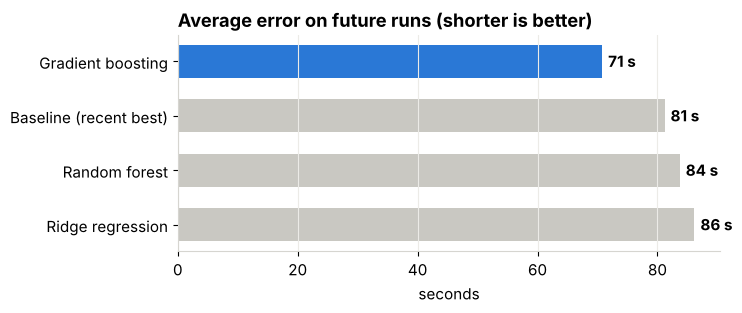

Winner: Gradient boosting


In [4]:
bundle = train(data)
NAMES = {"ridge": "Ridge regression", "random_forest": "Random forest",
         "gradient_boosting": "Gradient boosting", "baseline_recent_best": "Baseline (recent best)"}
scores = pd.Series(bundle["scores"]).sort_values().rename(index=NAMES)

fig, ax = plt.subplots(figsize=(7, 2.8))
colors = ["#2a78d6" if name == NAMES[bundle["name"]] else "#c9c8c2" for name in scores.index]
ax.barh(scores.index[::-1], scores.values[::-1], color=colors[::-1], height=0.6)
for i, v in enumerate(scores.values[::-1]):
    ax.text(v + 1, i, f"{v:.0f} s", va="center", fontweight="bold")
ax.set(title="Average error on future runs (shorter is better)", xlabel="seconds")
ax.grid(axis="y", visible=False)
plt.show()
print(f"Winner: {NAMES[bundle['name']]}")

## 5. Your predicted 5K

In [5]:
pred = current_prediction(runs, bundle)
err = bundle["scores"][bundle["name"]]
print(f"Predicted 5K if you raced tomorrow: {fmt(pred)}  ({fmt(pred / 5)} /km), usually within ±{err:.0f} s")

Predicted 5K if you raced tomorrow: 28:19  (5:40 /km), usually within ±71 s


## 6. What matters most
**Permutation importance**: shuffle one feature at a time and measure how much worse the winning model gets. A bigger drop means it matters more.

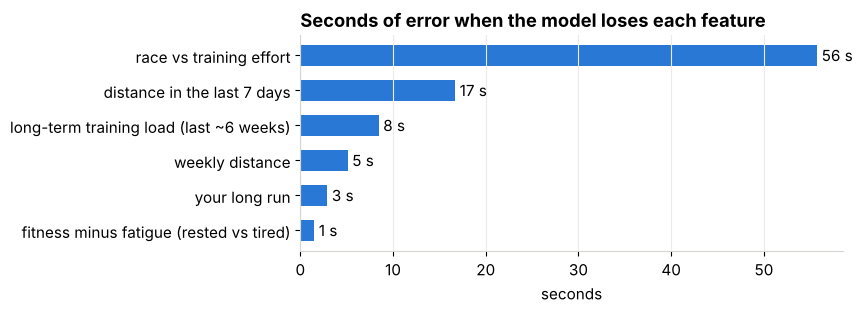

In [6]:
imp = bundle["importance"].head(6).rename(index=EXPLAIN)
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(imp.index[::-1], imp.values[::-1], color="#2a78d6", height=0.6)
for i, v in enumerate(imp.values[::-1]):
    ax.text(v + 0.5, i, f"{v:.0f} s", va="center")
ax.set(title="Seconds of error when the model loses each feature", xlabel="seconds")
ax.grid(axis="y", visible=False)
plt.show()

## 7. Best 4-week plans
The winner tries about 70 plans (mileage, runs per week, hard sessions, long run, taper) and predicts the 5K at the end of each. Mileage never grows more than 10% a week.

In [7]:
plans = best_plans(runs, bundle, top=5)
plans.insert(0, "predicted 5K", plans.pop("predicted_5k").map(fmt))
plans

,predicted 5K,weekly_km,runs_per_week,hard_sessions,long_run_share,taper_last_week,race_day
0,27:58,48 → 53 → 58 → 64,5,1,25%,True,2026-12-07
1,28:00,48 → 53 → 58 → 64,5,2,33%,True,2026-12-07
2,28:00,48 → 53 → 58 → 64,5,2,25%,True,2026-12-07
3,28:04,44 → 44 → 44 → 44,5,1,25%,False,2026-12-07
4,28:06,48 → 53 → 58 → 64,5,1,33%,True,2026-12-07


---
**Try next:** change `n_estimators` or `max_depth` in `runml/model.py`, or add a model (e.g. `LassoCV`) to `candidates()`, then re-run.
Little data, like only a few races? The [Run Coach](https://didilelass.github.io/didilelass/running-coach/) phone app uses a Bayesian model made for that.